# Exercise 67 – The particle in a box with a PINN

**Week 14 · Physics-informed neural networks**

The time-independent Schrödinger equation (with $\hbar = m = 1$)

$$-\frac12\,\psi''(x) + V(x)\,\psi(x) = E\,\psi(x), \qquad \psi(\pm\tfrac12) = 0$$

is an *eigenvalue* problem: both $\psi$ and $E$ are unknown. The network
represents $\psi$, and $E$ is an extra trainable parameter. Two choices make
training robust:

* the boundary condition is built into the model,
  $\psi(x) = (\tfrac14 - x^2)\,\mathrm{NN}(x)$, so it holds exactly;
* a normalisation term $10\,(\int\psi^2\,dx - 1)^2$ is added to the loss –
  without it $\psi = 0$ would be a perfect solution.

For the empty box the ground state is $\psi = \sqrt{2}\cos(\pi x)$ with
$E = \pi^2/2 \approx 4.93$. With a barrier we compare with a finite-difference
solution of the same equation.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

from comphy.pinn import PINN, train_pinn

torch.manual_seed(0)
L = 0.5
x_grid = torch.linspace(-L, L, 100).view(-1, 1)


class WavefunctionPINN(PINN):
    def __init__(self, depth=2, width=8, E=1.0):
        super().__init__(depth, width)
        self.E = nn.Parameter(torch.tensor(E))

    def forward(self, x):
        return (L**2 - x**2) * super().forward(x)      # ψ(±L) = 0 exactly


def normalisation(model):
    psi = model(x_grid).flatten()
    return 10 * (torch.trapezoid(psi**2, x_grid.flatten()) - 1) ** 2


def schrodinger(model, V=None):
    def residual(x, psi, dpsi, d2psi):
        potential = 0 if V is None else V(x) * psi
        return -0.5 * d2psi + potential - model.E * psi
    return residual


def finite_difference(V0, width=0.2, n=1000):
    """Ground state of the same problem on a grid, as a reference."""
    x = np.linspace(-L, L, n + 2)[1:-1]
    h = x[1] - x[0]
    H = (np.diag(1 / h**2 + V0 * (np.abs(x) < width / 2))
         - 0.5 / h**2 * (np.eye(n, k=1) + np.eye(n, k=-1)))
    E, vecs = np.linalg.eigh(H)
    psi = vecs[:, 0] / np.sqrt(h)
    return E[0], x, psi**2

## Empty box

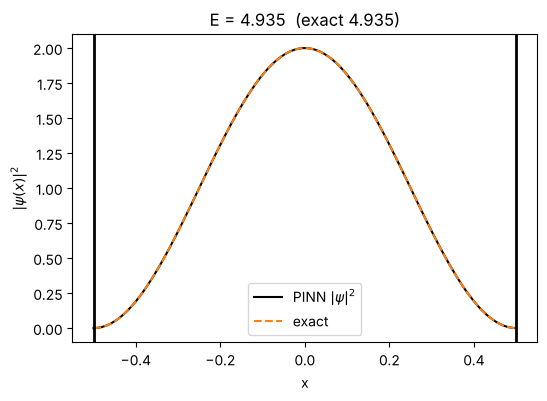

In [2]:
model = WavefunctionPINN()
train_pinn(model, schrodinger(model), x_range=(-L, L), epochs=10_000, order=2,
           extra_loss=normalisation, n_collocation=32)

with torch.no_grad():
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(x_grid, model(x_grid) ** 2, color="black", label="PINN $|\\psi|^2$")
    ax.plot(x_grid, 2 * torch.cos(math.pi * x_grid) ** 2, "--", color="C1", label="exact")
    for x in (-L, L):
        ax.axvline(x, color="black", lw=2)
    ax.set(xlim=(-0.55, 0.55), xlabel="x", ylabel="$|\\psi(x)|^2$",
           title=f"E = {model.E.item():.3f}  (exact {math.pi**2 / 2:.3f})")
    ax.legend()
plt.show()

## Adding a barrier in the middle
A rectangular barrier of width 0.2 and height $V_0$ pushes the particle
towards the walls. Each run continues from the previous solution.

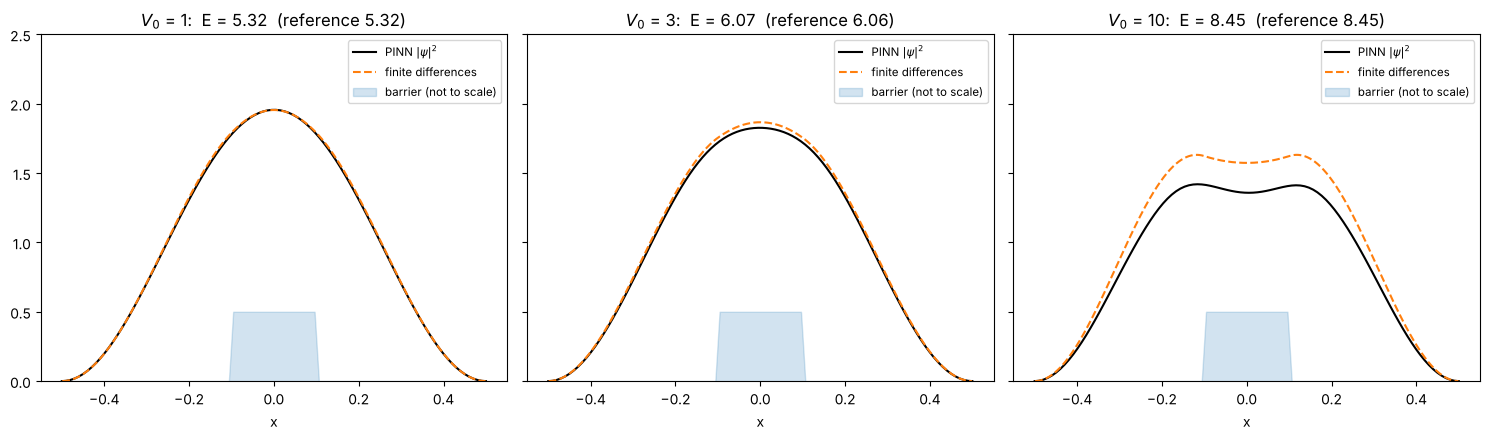

In [3]:
def barrier(height, width=0.2):
    return lambda x: height * (x.abs() < width / 2).float()


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, V0 in zip(axes, [1, 3, 10]):
    V = barrier(V0)
    train_pinn(model, schrodinger(model, V), x_range=(-L, L), epochs=10_000, order=2,
               extra_loss=normalisation, n_collocation=64)
    E_fd, x_fd, p_fd = finite_difference(V0)
    with torch.no_grad():
        ax.plot(x_grid, model(x_grid) ** 2, color="black", label="PINN $|\\psi|^2$")
        ax.plot(x_fd, p_fd, "--", color="C1", label="finite differences")
        ax.fill_between(x_grid.flatten(), V(x_grid).flatten() / V0 * 0.5, color="C0",
                        alpha=0.2, label="barrier (not to scale)")
    ax.set(xlim=(-0.55, 0.55), ylim=(0, 2.5), xlabel="x",
           title=f"$V_0$ = {V0}:  E = {model.E.item():.2f}  (reference {E_fd:.2f})")
    ax.legend(loc="upper right", fontsize="small")
fig.tight_layout()
plt.show()

The PINN energies agree with the finite-difference reference to two
decimals, and the wavefunctions have the right shape: as the barrier grows,
the probability in the middle drops and the energy rises. For the highest
barrier $|\psi|^2$ comes out slightly too small – the soft normalisation
penalty has not fully converged there.